<a href="https://colab.research.google.com/github/klavarihards/Markets-Strategies/blob/main/portfolio-engine/notebooks/06_taiwan_reality_check.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taiwan Reality Check: Taiwan Cash Rates and the Real Taiwan-Listed Funds

The research used long-history US-listed proxies (EWT, SPY, EFA+EEM, TLT, IEF, GLD) and a US T-bill rate for cash. A Taiwan client would hold Taiwan-listed funds, most of them Yuanta products, and keep cash in a TWD deposit. This notebook asks two questions:

1. **Cash at Taiwan rates.** Cash becomes a TWD deposit at the five major banks' 1-month rate (Central Bank of the Republic of China statistics), also used as the risk-free rate. The frozen portfolios (`configs/final_choice.yaml`), every method and the benchmarks are re-run. *Nothing is re-selected: the hold-out has already been opened.*
2. **The real funds.** From June 2017, when all six funds trade, each frozen portfolio's actual trade history is replayed with the proxies and with the Taiwan-listed funds, to measure how far a real client's result would drift from the research.

| Sleeve | Research proxy | Taiwan-listed fund |
|---|---|---|
| Taiwan equity | EWT | 0050 Yuanta Taiwan Top 50 |
| US equity | SPY | 00646 Yuanta S&P 500 |
| International equity | EFA + EEM | 00645 Fubon TOPIX (Japan) |
| Long US Treasuries | TLT | 00679B Yuanta US Treasury 20+ Year |
| Intermediate Treasuries | IEF | 00697B Yuanta US Treasury 7-10 Year |
| Gold | GLD | 00635U Yuanta S&P GSCI Gold ER Futures |
| Cash | US T-bill | TWD deposit (five major banks, 1-month) |

*Educational research project; fund names are representative Taiwan-listed instruments, not recommendations.*

In [1]:
# Setup: clone the repo (in Colab) and install the package, plus the libraries used for cross-checks.
import os, sys

IN_COLAB = "google.colab" in sys.modules
BRANCH = "claude/eloquent-fermat-i94z76"     # change to "main" once the branch is merged

if IN_COLAB:
    os.chdir("/content")
    if not os.path.exists("Markets-Strategies"):
        !git clone -q -b {BRANCH} https://github.com/klavarihards/Markets-Strategies.git
    else:
        !git -C Markets-Strategies fetch -q origin {BRANCH} && git -C Markets-Strategies checkout -q {BRANCH} && git -C Markets-Strategies pull -q origin {BRANCH}
    os.chdir("Markets-Strategies/portfolio-engine")
    !pip install -q -e ".[download,crosscheck]"
    sys.path.insert(0, "src")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working directory:", os.getcwd())

# In Colab, keep data snapshots and results on Google Drive: a Colab runtime's own files
# disappear when it restarts, and the snapshot must stay the same for every later run.
# The repo's data/snapshots and results folders become links to Drive, so nothing else changes.
USE_DRIVE = IN_COLAB
if USE_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    store = "/content/drive/MyDrive/portfolio-engine"
    for local, remote in [("data/snapshots", f"{store}/snapshots"), ("results", f"{store}/results")]:
        os.makedirs(remote, exist_ok=True)
        if not os.path.islink(local):
            if os.path.isdir(local):
                shutil.copytree(local, remote, dirs_exist_ok=True)   # keep anything already there
                shutil.rmtree(local)
            os.makedirs(os.path.dirname(local) or ".", exist_ok=True)
            os.symlink(remote, local)
    print("Snapshots and results are stored in", store)

Working directory: /home/user/Markets-Strategies/portfolio-engine


Config e4683586d1e7 | Taiwan snapshot downloaded 2026-10-24


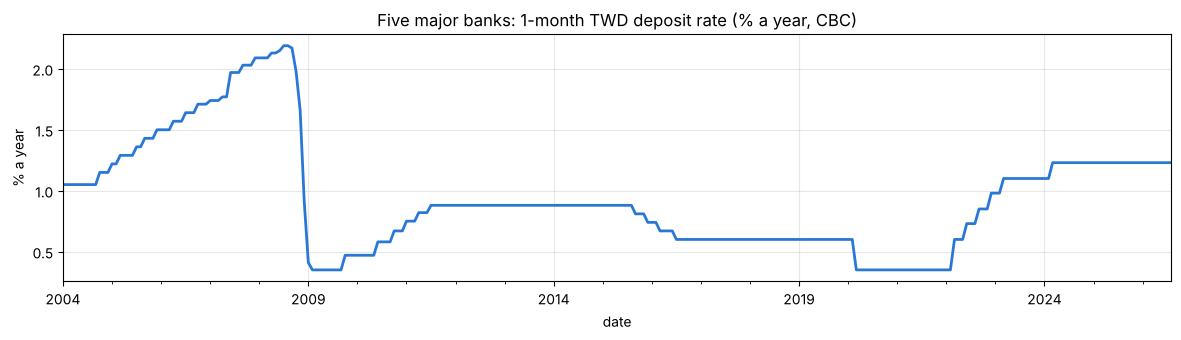

In [2]:
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio_engine.config import load_config, config_hash
from portfolio_engine.data import read_snapshot, resolve_snapshot
from portfolio_engine.backtest.taiwan import taiwan_reality_check, save_reality_check

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
cfg = load_config("configs/taiwan.yaml")
choice = yaml.safe_load(open("configs/final_choice.yaml"))
tw, manifest = read_snapshot(resolve_snapshot(cfg["taiwan"]["snapshot_dir"]))
print("Config", config_hash(cfg), "| Taiwan snapshot downloaded", manifest["downloaded_on"])
rates = tw["bank_rates"]["1-month deposit rates"].loc["2004":]
ax = rates.plot(figsize=(12, 3.5), color="#2a78d6", linewidth=2, title="Five major banks: 1-month TWD deposit rate (% a year, CBC)")
ax.grid(True, alpha=0.3); ax.set_ylabel("% a year"); plt.tight_layout(); plt.show()

In [3]:
out = taiwan_reality_check(cfg, choice)       # all data: allowed, the hold-out evaluation is logged
run_dir = save_reality_check(out, cfg)
print("Data", out["data"].snapshot_id, "| funds all trade from", out["funds_start"], "| saved to", run_dir)

Data 570bdef9e8ea+005d4d80deef | funds all trade from 2017-06-16 | saved to results/taiwan_reality_check_e4683586d1e7_570bdef9e8ea+005d4d80deef_holdout


## 1. Cash at Taiwan rates: the frozen portfolios and benchmarks

Development period (to 22 Oct 2024) and hold-out (23 Oct 2024 – 22 Oct 2026), 3-year window, after costs, Sharpe against the TWD deposit rate.

In [4]:
cols = ["ann_return", "ann_vol", "sharpe", "max_drawdown"]
fmt = {"ann_return": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.1%}"}
both = pd.concat({"development": out["cash_tables"]["dev"][cols], "hold-out": out["cash_tables"]["holdout"][cols]}, axis=1)
both.style.format({c: fmt[c[1]] for c in both.columns})

## 2. How far each Taiwan-listed fund drifts from its proxy

Monthly returns in TWD, from June 2017. A positive gap means the Taiwan-listed fund returned more than the proxy.

,months,correlation,tracking_error,proxy_ann_return,fund_ann_return,return_gap
taiwan_equity,113,0.93,8.0%,19.3%,23.7%,+4.4%
us_equity,113,0.94,5.1%,15.5%,14.6%,-0.9%
intl_equity,113,0.68,10.7%,8.4%,11.5%,+3.2%
long_treasury,113,0.94,4.3%,-1.0%,-1.3%,-0.3%
intermediate_bond,113,0.96,2.0%,1.3%,0.9%,-0.4%
gold,113,0.87,7.9%,13.5%,8.3%,-5.3%


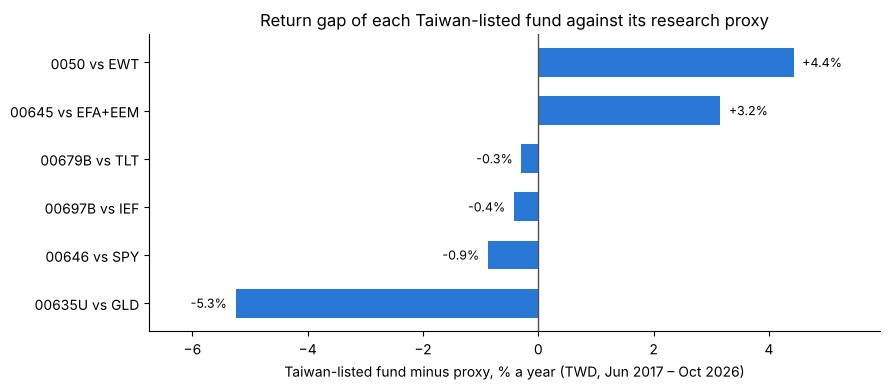

Data checks: {'0050.TW': {'repairs': [], 'flagged': {'2025-04-07': -0.1}}, '00646.TW': {'repairs': [], 'flagged': {'2025-04-07': -0.1259, '2025-04-10': 0.1039}}, '00645.TW': {'repairs': [], 'flagged': {'2024-08-05': -0.132, '2025-04-07': -0.1258}}, '00635U.TW': {'repairs': [], 'flagged': {'2026-02-02': -0.1109}}}


In [5]:
d = out["drift"]
display(d.style.format({"months": "{:.0f}", "correlation": "{:.2f}", "tracking_error": "{:.1%}",
                        "proxy_ann_return": "{:.1%}", "fund_ann_return": "{:.1%}", "return_gap": "{:+.1%}"}))
names = {"taiwan_equity": "0050 vs EWT", "us_equity": "00646 vs SPY", "intl_equity": "00645 vs EFA+EEM",
         "long_treasury": "00679B vs TLT", "intermediate_bond": "00697B vs IEF", "gold": "00635U vs GLD"}
g = d["return_gap"].rename(index=names).sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(g.index, 100 * g.values, color="#2a78d6", height=0.6)
for i, v in enumerate(g.values):
    ax.text(100 * v + (0.15 if v >= 0 else -0.15), i, f"{100 * v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlabel("Taiwan-listed fund minus proxy, % a year (TWD, Jun 2017 – Oct 2026)")
ax.set_title("Return gap of each Taiwan-listed fund against its research proxy")
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.set_xlim(100 * g.min() - 1.5, 100 * g.max() + 1.5)
plt.tight_layout(); plt.show()
print("Data checks:", {k: v for k, v in out["quality"].items() if v["repairs"] or v["flagged"]})

## 3. The frozen portfolios, held with the real funds

The same trades, replayed with the proxies (as researched) and with the Taiwan-listed funds (executed the next Taipei trading day; spreads, commission and the 0.1% sell tax charged, fund fees already in the prices).

,proxy_ann_return,fund_ann_return,return_gap,proxy_max_drawdown,fund_max_drawdown,proxy_sharpe,fund_sharpe,monthly_correlation,tracking_error
portfolio,,,,,,,,,
conservative:min_cvar|all,4.7%,5.7%,+1.0%,-7.7%,-7.6%,0.78,1.07,0.92,1.7%
equal_weight,8.5%,9.3%,+0.8%,-12.9%,-12.7%,0.89,1.07,0.91,3.0%
sixty_forty,8.9%,10.8%,+1.9%,-17.4%,-15.7%,0.77,1.02,0.91,3.9%
taiwan_equity_only,19.2%,24.4%,+5.1%,-29.0%,-33.8%,0.89,1.11,0.93,8.1%
balanced:min_cvar|regime_hmm,5.8%,7.0%,+1.2%,-10.3%,-10.5%,0.77,0.93,0.85,3.0%
growth:black_litterman|all,8.4%,9.7%,+1.4%,-18.2%,-17.5%,0.71,0.87,0.90,4.1%


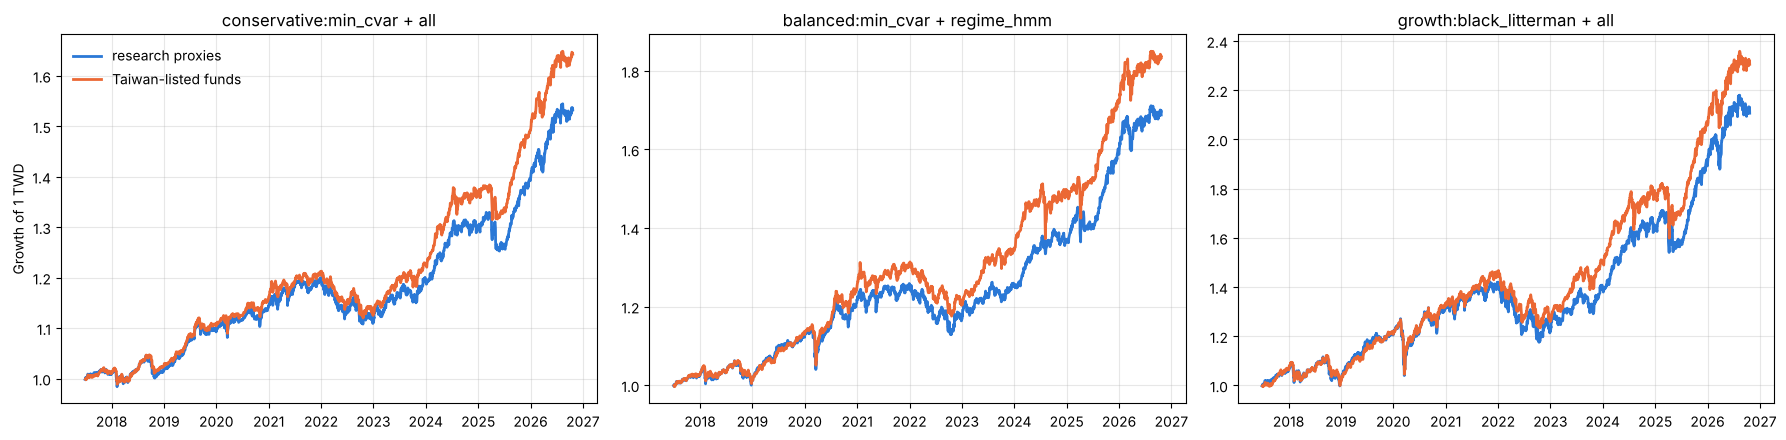

In [6]:
imp = out["implementation"]
show = ["proxy_ann_return", "fund_ann_return", "return_gap", "proxy_max_drawdown", "fund_max_drawdown",
        "proxy_sharpe", "fund_sharpe", "monthly_correlation", "tracking_error"]
display(imp[show].style.format({c: ("{:.2f}" if "sharpe" in c or "correlation" in c else "{:+.1%}" if c == "return_gap" else "{:.1%}") for c in show}))
frozen = [n for n in out["series"] if ":" in n]
fig, axes = plt.subplots(1, len(frozen), figsize=(18, 4.5), sharey=False)
for ax, n in zip(axes, frozen):
    for kind, color, label in (("proxy", "#2a78d6", "research proxies"), ("fund", "#eb6834", "Taiwan-listed funds")):
        s = out["series"][n][kind]
        ax.plot((1 + s).cumprod(), color=color, linewidth=2, label=label)
    ax.set_title(n.replace("|", " + ")); ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Growth of 1 TWD"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## Findings

*Written after the run; every number is from the tables above.*

- **Taiwan cash changes the levels, not the conclusions.** With cash as a TWD deposit (1-month rate between 0.35% and 2.2% since 2004, against US T-bills of up to 5%), the conservative choice's development return falls slightly and its Sharpe rises (0.74 against the TWD rate, worst drawdown -7.7%). Min-CVaR is still the only method that keeps a conservative client inside the -10% limit (-6.1%, others -11.7% to -16.5%). In the hold-out the conservative choice earned 8.5% a year instead of 9.5%: its cash now earns the TWD deposit rate (about 1.2%) instead of the much higher US T-bill rate.
- **The Taiwan-listed funds track their proxies closely, except gold.** Monthly correlations are 0.87–0.96 for five of six sleeves. 0050 returned 4.4% a year more than EWT (different index, US-listed costs and withholding). 00635U lagged spot gold by 5.3% a year: it tracks a gold futures excess-return index, so roll costs, fees and the interest a futures position does not earn all show up against spot gold. 00645 (Fubon TOPIX) is the weakest match (correlation 0.68): it holds Japan only, the proxy is half developed, half emerging markets.
- **Held with the real funds, the frozen portfolios did better, not worse.** From July 2017 the three choices returned 1.0–1.4% a year more with the Taiwan funds than with the proxies, with tracking error of 1.7–4.1% a year and similar worst drawdowns. About 0.7% a year of that is the funds' own returns (gaps that partly cancel: 0050 and 00645 ahead of their proxies, 00635U behind); 0.2–0.6% is because the research charged holding costs (extra fund fees, withholding, FX spreads) that the funds' prices already contain; next-day trading adds 0.0–0.1%. The research's cost assumptions were conservative for a client holding these funds.
- **Caveat:** nine years with one long Taiwan boom. 0050's lead over EWT likely comes in large part from its heavier TSMC weight, which works in both directions.
